# Water condition classifier: EDA and model building

Dataset: readings recorded by the ESP32 on 3 Nov 2026 and exported from the dashboard.
Each reading is one row (every 3 s) with only the timestamp, the water sensors and the label.
Readings taken while a pump ran are already left out by the export. The `label` column was set on the dashboard while
recording each kind of water:

| Label | How the water was prepared |
|---|---|
| `clear` | clean tap water |
| `slightly_turbid` | clean water with salt and a little milk |
| `dirty` | more salt and milk added |

Goal: predict the label from the sensor values, compare several models, and pick one small
enough to run on the ESP32.

Steps:
1. Load the data
2. Data overview
3. Cleaning
4. Exploratory data analysis (EDA)
5. Feature selection
6. Train/test split
7. Model training and comparison
8. Evaluation of the models
9. Which model fits on the ESP32
10. Save the models

## 1. Load the data

In [1]:
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score)
from sklearn.model_selection import GroupKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

DATA = "data/iot_project_dataset_2026-11-03_labelled.csv"
LABELS = ["clear", "slightly_turbid", "dirty"]
COLORS = {"clear": "#2a9d8f", "slightly_turbid": "#e9c46a", "dirty": "#a0522d"}
RANDOM_STATE = 42
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

COLUMNS = ["timestamp_wib", "t_tank", "tds", "tds_v", "turb", "turb_v", "label"]
raw = pd.read_csv(DATA)
missing = [c for c in COLUMNS if c not in raw.columns]
assert not missing, f"CSV is missing columns: {missing}"
raw = raw[COLUMNS].copy()
raw["time"] = pd.to_datetime(raw["timestamp_wib"])
print("Rows:", len(raw), " Columns:", raw.shape[1])
raw.head()

Rows: 1031  Columns: 8


,timestamp_wib,t_tank,tds,tds_v,turb,turb_v,label,time
0,2026-11-03 19:44:46,21.44,277.5,0.696,6.7,1.700,clear,2026-11-03 19:44:46
1,2026-11-03 19:44:49,21.44,277.5,0.696,6.8,1.699,clear,2026-11-03 19:44:49
2,2026-11-03 19:44:52,21.44,277.5,0.696,6.6,1.700,clear,2026-11-03 19:44:52
3,2026-11-03 19:44:55,21.44,277.4,0.696,6.9,1.698,clear,2026-11-03 19:44:55
4,2026-11-03 19:44:59,21.44,277.5,0.696,7.0,1.698,clear,2026-11-03 19:44:59


Column meaning:

| Column | Meaning |
|---|---|
| `timestamp_wib` | time of the reading (WIB) |
| `t_tank` | water temperature from the DS18B20 (°C) |
| `tds`, `tds_v` | TDS in ppm (temperature compensated) and its raw voltage |
| `turb`, `turb_v` | turbidity index 0-100 and the raw sensor voltage (higher V = clearer) |
| `label` | water condition set on the dashboard (target) |

Float switches, score, pump and mode columns are not part of the dataset: they describe the
device, not the water, so they are not used to train the model.

## 2. Data overview

In [2]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1031 entries, 0 to 1030
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   timestamp_wib  1031 non-null   object        
 1   t_tank         1031 non-null   float64       
 2   tds            1031 non-null   float64       
 3   tds_v          1031 non-null   float64       
 4   turb           1031 non-null   float64       
 5   turb_v         1031 non-null   float64       
 6   label          1026 non-null   object        
 7   time           1031 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(5), object(2)
memory usage: 64.6+ KB


In [3]:
raw.describe().T

,count,mean,min,25%,50%,75%,max,std
t_tank,1031.0,22.149,21.38,21.56,22.5,22.56,22.88,0.491
tds,1031.0,549.969,260.3,277.0,358.0,968.85,981.6,309.026
tds_v,1031.0,1.243,0.652,0.695,0.927,2.013,2.027,0.576
turb,1031.0,51.462,0.0,5.9,69.4,82.5,95.7,35.779
turb_v,1031.0,1.577,1.293,1.425,1.556,1.71,2.519,0.174
time,1031,2026-11-03 20:19:47.419980544,2026-11-03 19:44:46,2026-11-03 19:59:00.500000,2026-11-03 20:24:02,2026-11-03 20:37:35.500000,2026-11-03 20:51:18,NaN


In [4]:
print("Missing values per column:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print()
print("Rows per label (NaN = no label):")
print(raw["label"].value_counts(dropna=False))

Missing values per column:
label    5
dtype: int64

Rows per label (NaN = no label):
label
dirty              361
clear              334
slightly_turbid    331
NaN                  5
Name: count, dtype: int64


In [5]:
# Each label was recorded as one continuous session
raw.groupby(raw["label"].fillna("(none)"))["time"].agg(["min", "max", "count"])

,min,max,count
label,,,
(none),2026-11-03 20:02:53,2026-11-03 20:03:05,5
clear,2026-11-03 19:44:46,2026-11-03 20:02:50,334
dirty,2026-11-03 20:31:53,2026-11-03 20:51:18,361
slightly_turbid,2026-11-03 20:03:08,2026-11-03 20:31:50,331


## 3. Cleaning

Rows that are removed:
- **No label** (5 rows): recorded while the salt was being poured in, the water was not
  mixed yet (TDS jumps 427 → 620 → 517 ppm in 6 s).
- Readings taken while a pump ran (10 rows in this recording) are not in the file: the
  dashboard export leaves them out because the pump disturbs the turbidity reading.
- **Missing temperature**: none in this file, but the check stays for future datasets.

The `turb` index column was recorded with an older calibration, so the raw voltage
`turb_v` is used for turbidity instead. The voltage does not depend on calibration.

In [6]:
df = raw.copy()
steps = [("start", len(df))]

df = df.dropna(subset=["label"])
steps.append(("drop unlabelled rows", len(df)))

df = df.dropna(subset=["t_tank", "tds", "turb_v"])
steps.append(("drop rows with missing sensor values", len(df)))

df = df.sort_values("time").reset_index(drop=True)
df["label"] = pd.Categorical(df["label"], categories=LABELS, ordered=True)

print(pd.DataFrame(steps, columns=["step", "rows left"]).to_string(index=False))
print()
print(df["label"].value_counts().sort_index())

                                step  rows left
                               start       1031
                drop unlabelled rows       1026
drop rows with missing sensor values       1026

label
clear              334
slightly_turbid    331
dirty              361
Name: count, dtype: int64


## 4. Exploratory data analysis

### 4.1 Statistics per label

In [7]:
SENSORS = ["tds", "turb_v", "t_tank"]
df.groupby("label", observed=True)[SENSORS].agg(["mean", "std", "min", "max"]).T

label          clear  slightly_turbid    dirty
tds    mean  276.287          375.684  963.845
       std     1.177           50.280   39.862
       min   260.300          346.100  650.300
       max   277.900          781.400  981.600
turb_v mean    1.721            1.597    1.417
       std     0.019            0.178    0.074
       min     1.690            1.448    1.293
       max     1.764            2.398    1.675
t_tank mean   21.521           22.400   22.508
       std     0.056            0.375    0.039
       min    21.380           21.560   22.440
       max    21.630           22.630   22.880

### 4.2 Class balance

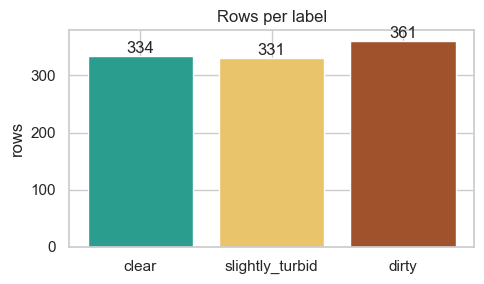

In [8]:
fig, ax = plt.subplots(figsize=(5, 3))
counts = df["label"].value_counts().reindex(LABELS)
ax.bar(counts.index, counts.values, color=[COLORS[l] for l in LABELS])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_ylabel("rows")
ax.set_title("Rows per label")
fig.tight_layout()
fig.savefig("results/class_balance.png", dpi=150)
plt.show()

The three labels have a similar number of rows, so accuracy is not misleading here.

### 4.3 Sensor values over time

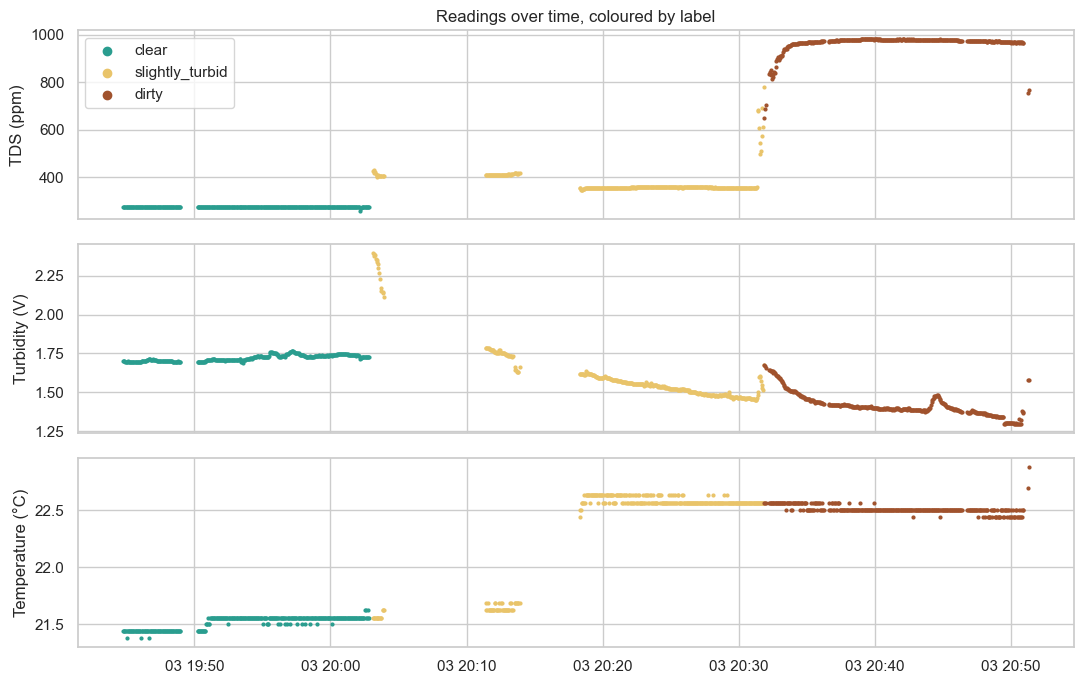

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
names = {"tds": "TDS (ppm)", "turb_v": "Turbidity (V)", "t_tank": "Temperature (°C)"}
for ax, col in zip(axes, SENSORS):
    for label in LABELS:
        part = df[df["label"] == label]
        ax.scatter(part["time"], part[col], s=4, color=COLORS[label], label=label)
    ax.set_ylabel(names[col])
axes[0].legend(loc="upper left", markerscale=3)
axes[0].set_title("Readings over time, coloured by label")
fig.tight_layout()
fig.savefig("results/time_series.png", dpi=150)
plt.show()

- **TDS** is flat inside each session and very different between them (≈276 / ≈376 / ≈960 ppm).
- **Turbidity voltage** goes down as the water gets dirtier, but it moves around inside a
  session (lens drift and bubbles) and the ranges overlap.
- **Temperature** changes by about 1 °C between sessions because of the room, not because
  of the water condition.

### 4.4 Distribution per label

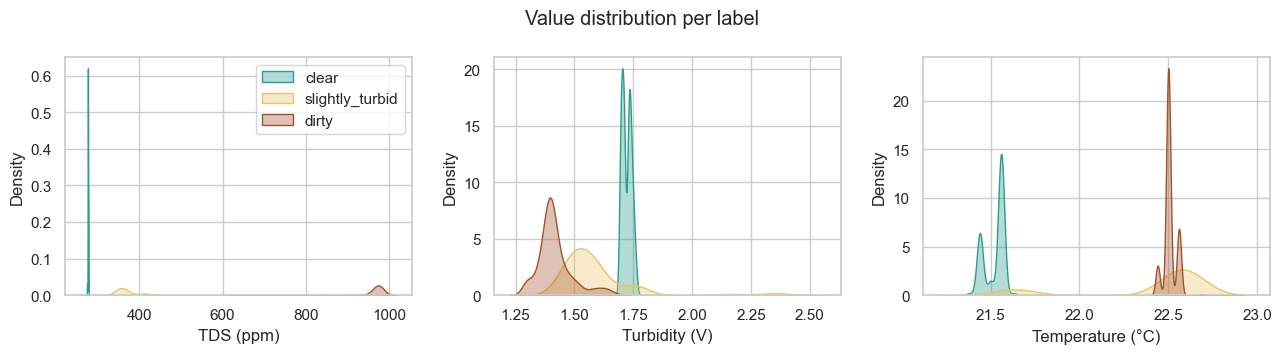

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, SENSORS):
    for label in LABELS:
        sns.kdeplot(df.loc[df["label"] == label, col], ax=ax, fill=True, alpha=0.35,
                    color=COLORS[label], label=label, warn_singular=False)
    ax.set_xlabel(names[col])
axes[0].legend()
fig.suptitle("Value distribution per label")
fig.tight_layout()
fig.savefig("results/distributions.png", dpi=150)
plt.show()

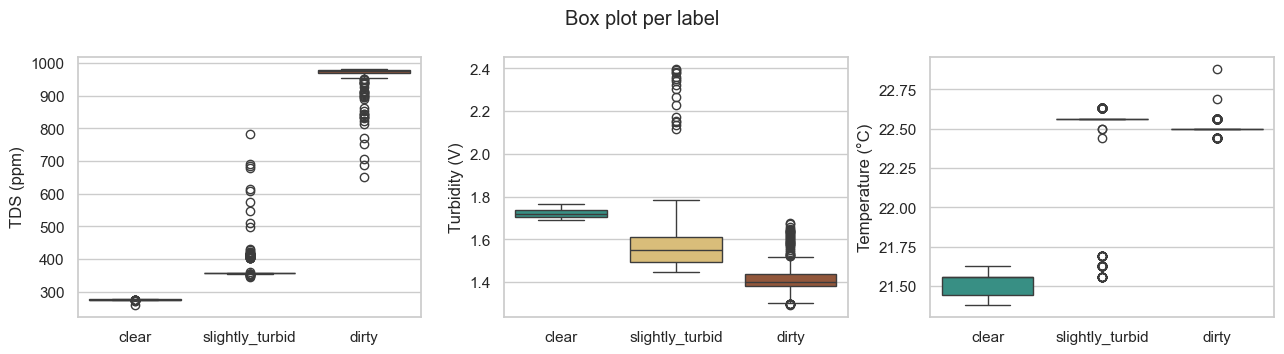

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, SENSORS):
    sns.boxplot(data=df, x="label", y=col, order=LABELS, palette=COLORS, ax=ax)
    ax.set_xlabel("")
    ax.set_ylabel(names[col])
fig.suptitle("Box plot per label")
fig.tight_layout()
fig.savefig("results/boxplots.png", dpi=150)
plt.show()

### 4.5 TDS against turbidity

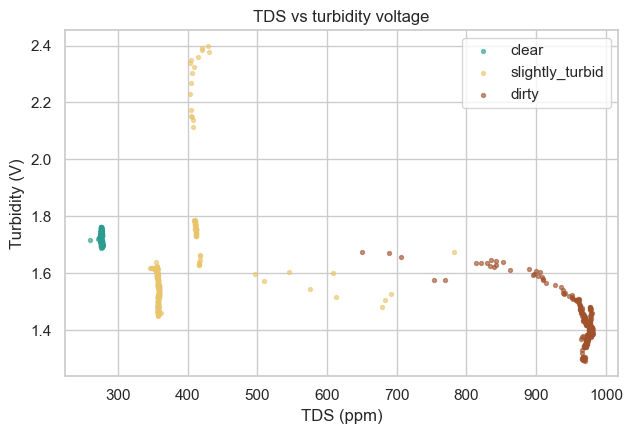

In [12]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for label in LABELS:
    part = df[df["label"] == label]
    ax.scatter(part["tds"], part["turb_v"], s=8, alpha=0.6, color=COLORS[label], label=label)
ax.set_xlabel("TDS (ppm)")
ax.set_ylabel("Turbidity (V)")
ax.set_title("TDS vs turbidity voltage")
ax.legend()
fig.tight_layout()
fig.savefig("results/scatter_tds_turb.png", dpi=150)
plt.show()

### 4.6 Correlation

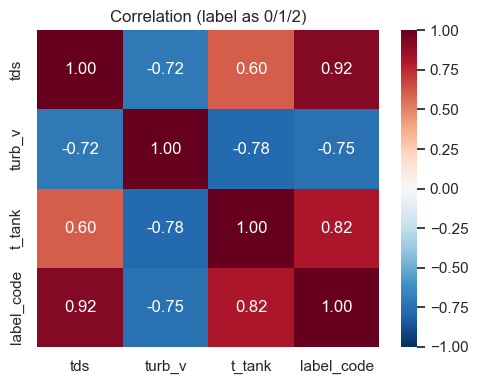

In [13]:
corr_df = df[SENSORS].copy()
corr_df["label_code"] = df["label"].cat.codes   # 0 clear, 1 slightly_turbid, 2 dirty
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation (label as 0/1/2)")
fig.tight_layout()
fig.savefig("results/correlation.png", dpi=150)
plt.show()

### 4.7 EDA findings

1. TDS separates the three labels almost perfectly, because salt was added for each level.
2. Turbidity voltage follows the label (clear water is highest), but it overlaps between
   `clear` and `slightly_turbid` and drifts within a session.
3. Temperature differs between sessions only because the room temperature changed. A model
   that uses it would learn *when* the water was recorded instead of *how dirty* it is.
4. Each label is one continuous session, so neighbouring rows are nearly identical. This
   matters for how the data is split (section 6).

## 5. Feature selection

Feature sets compared:
- `tds + turb_v`: main choice, both sensors that describe the water.
- `tds` only and `turb_v` only: to see how much each sensor contributes.
- `tds + turb_v + t_tank`: to check whether temperature only adds session information.

All of these values are also available on the ESP32, so whichever set is chosen can run there.

In [14]:
FEATURE_SETS = {
    "tds + turb_v": ["tds", "turb_v"],
    "tds": ["tds"],
    "turb_v": ["turb_v"],
    "tds + turb_v + t_tank": ["tds", "turb_v", "t_tank"],
}
MAIN_FEATURES = FEATURE_SETS["tds + turb_v"]

## 6. Train/test split

A random split would put almost identical neighbouring readings in both train and test, so
the test score would look better than it is. Instead, **for each label the first 75 % of the
recording is used for training and the last 25 % for testing** (time-ordered split).

For hyperparameter checks on the training data, each label's training part is cut into 4
consecutive blocks and `GroupKFold` keeps every block in one fold (blocked cross-validation).

In [15]:
TEST_FRAC = 0.25
N_BLOCKS = 4

train_parts, test_parts = [], []
for label, group in df.groupby("label", observed=True):
    cut = int(len(group) * (1 - TEST_FRAC))
    train_parts.append(group.iloc[:cut].assign(block=lambda g: np.arange(len(g)) * N_BLOCKS // len(g)))
    test_parts.append(group.iloc[cut:])
train = pd.concat(train_parts).reset_index(drop=True)
test = pd.concat(test_parts).reset_index(drop=True)

summary = pd.DataFrame({"train": train["label"].value_counts(), "test": test["label"].value_counts()}).reindex(LABELS)
print(summary)
print("\nTotal train:", len(train), " test:", len(test))

                 train  test
label                       
clear              250    84
slightly_turbid    248    83
dirty              270    91

Total train: 768  test: 258


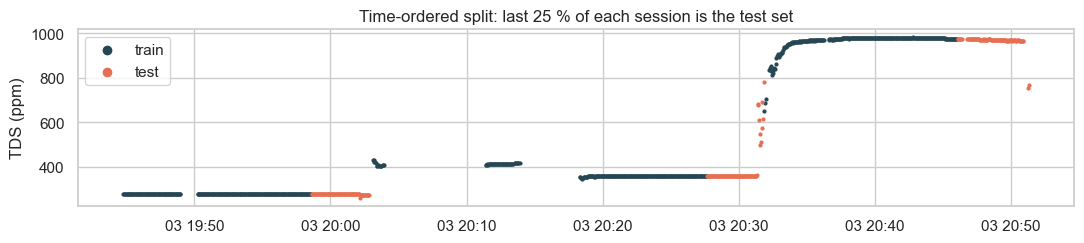

In [16]:
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.scatter(train["time"], train["tds"], s=4, color="#264653", label="train")
ax.scatter(test["time"], test["tds"], s=4, color="#e76f51", label="test")
ax.set_ylabel("TDS (ppm)")
ax.set_title("Time-ordered split: last 25 % of each session is the test set")
ax.legend(markerscale=3)
fig.tight_layout()
fig.savefig("results/split.png", dpi=150)
plt.show()

## 7. Model training and comparison

Models (all from scikit-learn):

| Model | Why it is included |
|---|---|
| Decision Tree | simple if-else rules, easy to export to the ESP32 |
| Random Forest | many trees, usually more robust than one tree |
| Gradient Boosting | strong tabular model, boosted trees |
| k-Nearest Neighbours | compares with the closest training readings |
| Logistic Regression | linear baseline |
| SVM (RBF kernel) | non-linear decision boundary |
| Gaussian Naive Bayes | very small probabilistic baseline |

Scale-sensitive models (k-NN, Logistic Regression, SVM) get a `StandardScaler` first.

In [17]:
def make_models():
    return {
        "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=RANDOM_STATE),
        "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=2, random_state=RANDOM_STATE),
        "k-NN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
        "Naive Bayes": GaussianNB(),
    }

### 7.1 Decision tree depth

The tree depth is picked with blocked cross-validation on the training data only.

 max_depth  cv_macro_f1   std
         1        0.554 0.003
         2        0.904 0.166
         3        0.904 0.166
         4        0.904 0.166
         5        0.904 0.166
         6        0.904 0.166


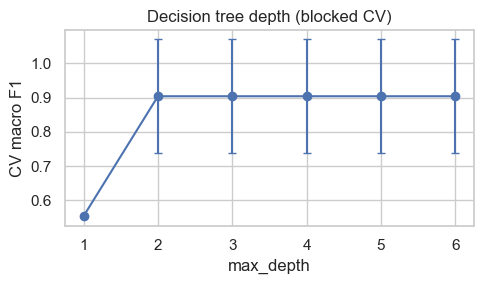

In [18]:
cv = GroupKFold(n_splits=N_BLOCKS)
rows = []
for depth in range(1, 7):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    scores = cross_val_score(tree, train[MAIN_FEATURES], train["label"], groups=train["block"],
                             cv=cv, scoring="f1_macro")
    rows.append((depth, scores.mean(), scores.std()))
depth_df = pd.DataFrame(rows, columns=["max_depth", "cv_macro_f1", "std"])
print(depth_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3))
ax.errorbar(depth_df["max_depth"], depth_df["cv_macro_f1"], yerr=depth_df["std"], marker="o", capsize=3)
ax.set_xlabel("max_depth")
ax.set_ylabel("CV macro F1")
ax.set_title("Decision tree depth (blocked CV)")
fig.tight_layout()
fig.savefig("results/tree_depth.png", dpi=150)
plt.show()

### 7.2 All models on the main features (`tds + turb_v`)

In [19]:
def evaluate(models, features):
    rows, fitted = [], {}
    for name, model in models.items():
        cv_f1 = cross_val_score(model, train[features], train["label"], groups=train["block"],
                                cv=cv, scoring="f1_macro").mean()
        model.fit(train[features], train["label"])
        pred = model.predict(test[features])
        rows.append({
            "model": name,
            "cv_macro_f1": cv_f1,
            "test_accuracy": accuracy_score(test["label"], pred),
            "test_macro_f1": f1_score(test["label"], pred, average="macro"),
        })
        fitted[name] = model
    return pd.DataFrame(rows).sort_values("test_macro_f1", ascending=False).reset_index(drop=True), fitted

results, fitted = evaluate(make_models(), MAIN_FEATURES)
results.to_csv("results/model_comparison.csv", index=False)
results

,model,cv_macro_f1,test_accuracy,test_macro_f1
0,Logistic Regression,0.901,0.984,0.985
1,k-NN (k=5),0.903,0.981,0.981
2,SVM (RBF),0.896,0.973,0.973
3,Decision Tree,0.904,0.969,0.969
4,Random Forest,0.829,0.969,0.969
5,Gradient Boosting,0.856,0.969,0.969
6,Naive Bayes,0.996,0.965,0.965


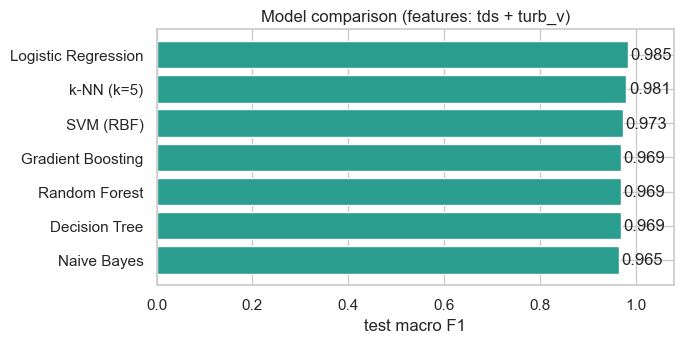

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.6))
order = results.sort_values("test_macro_f1")
ax.barh(order["model"], order["test_macro_f1"], color="#2a9d8f")
for y, v in enumerate(order["test_macro_f1"]):
    ax.text(v + 0.005, y, f"{v:.3f}", va="center")
ax.set_xlim(0, 1.08)
ax.set_xlabel("test macro F1")
ax.set_title("Model comparison (features: tds + turb_v)")
fig.tight_layout()
fig.savefig("results/model_comparison.png", dpi=150)
plt.show()

### 7.3 Feature sets

Every model is trained again on each feature set to see what each sensor adds.

In [21]:
feature_rows = []
for set_name, features in FEATURE_SETS.items():
    res, _ = evaluate(make_models(), features)
    for _, r in res.iterrows():
        feature_rows.append({"features": set_name, "model": r["model"], "test_macro_f1": r["test_macro_f1"]})
feature_table = pd.DataFrame(feature_rows).pivot(index="model", columns="features", values="test_macro_f1")
feature_table = feature_table[list(FEATURE_SETS)]
feature_table.to_csv("results/feature_sets.csv")
feature_table.style.format("{:.3f}").background_gradient(cmap="Greens", vmin=0.3, vmax=1.0)

features,tds + turb_v,tds,turb_v,tds + turb_v + t_tank
model,,,,
Decision Tree,0.969,0.969,0.698,0.969
Gradient Boosting,0.969,0.969,0.698,0.969
Logistic Regression,0.985,0.985,0.607,0.985
Naive Bayes,0.965,0.965,0.600,0.965
Random Forest,0.969,0.969,0.698,0.957
SVM (RBF),0.973,0.973,0.658,0.969
k-NN (k=5),0.981,0.973,0.657,0.981


### 7.4 Why the split matters

The same models with a **random** 75/25 split, for comparison. A higher score here only shows
that random splitting leaks near-duplicate readings into the test set.

In [22]:
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    df[MAIN_FEATURES], df["label"], test_size=TEST_FRAC, stratify=df["label"], random_state=RANDOM_STATE)
leak_rows = []
for name, model in make_models().items():
    model.fit(Xr_train, yr_train)
    leak_rows.append({"model": name, "random_split_macro_f1": f1_score(yr_test, model.predict(Xr_test), average="macro")})
leak = pd.DataFrame(leak_rows).merge(results[["model", "test_macro_f1"]], on="model")
leak = leak.rename(columns={"test_macro_f1": "time_split_macro_f1"})
leak

,model,random_split_macro_f1,time_split_macro_f1
0,Decision Tree,0.992,0.969
1,Random Forest,0.992,0.969
2,Gradient Boosting,0.992,0.969
3,k-NN (k=5),0.996,0.981
4,Logistic Regression,0.980,0.985
5,SVM (RBF),1.000,0.973
6,Naive Bayes,0.992,0.965


## 8. Evaluation

### 8.1 Confusion matrices

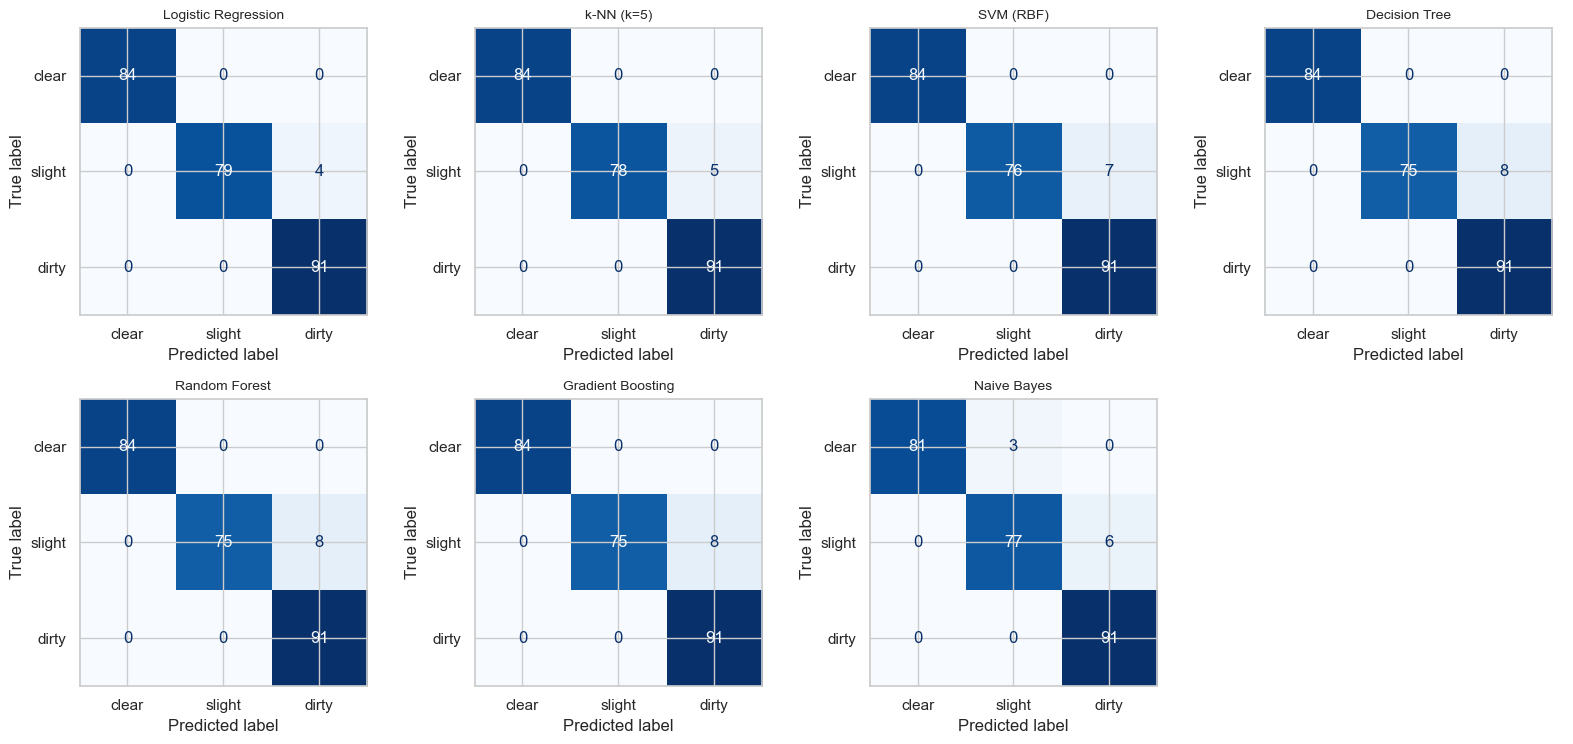

In [23]:
names_sorted = list(results["model"])
cols = 4
rows_n = int(np.ceil(len(names_sorted) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 3.8 * rows_n))
for ax, name in zip(axes.flat, names_sorted):
    pred = fitted[name].predict(test[MAIN_FEATURES])
    cm = confusion_matrix(test["label"], pred, labels=LABELS)
    ConfusionMatrixDisplay(cm, display_labels=["clear", "slight", "dirty"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10)
for ax in list(axes.flat)[len(names_sorted):]:
    ax.axis("off")
fig.tight_layout()
fig.savefig("results/confusion_matrices.png", dpi=150)
plt.show()

### 8.2 Classification report per model

In [24]:
for name in names_sorted:
    pred = fitted[name].predict(test[MAIN_FEATURES])
    print(f"=== {name} ===")
    print(classification_report(test["label"], pred, labels=LABELS, zero_division=0))

=== Logistic Regression ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        84
slightly_turbid       1.00      0.95      0.98        83
          dirty       0.96      1.00      0.98        91

       accuracy                           0.98       258
      macro avg       0.99      0.98      0.98       258
   weighted avg       0.99      0.98      0.98       258

=== k-NN (k=5) ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        84
slightly_turbid       1.00      0.94      0.97        83
          dirty       0.95      1.00      0.97        91

       accuracy                           0.98       258
      macro avg       0.98      0.98      0.98       258
   weighted avg       0.98      0.98      0.98       258

=== SVM (RBF) ===
                 precision    recall  f1-score   support

          clear       1.00      1.00      1.00        84
slightly_turbid 

### 8.3 Feature importance

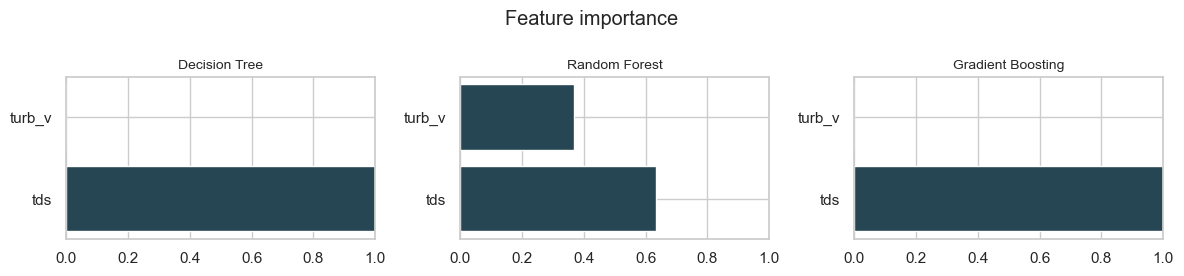

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
for ax, name in zip(axes, ["Decision Tree", "Random Forest", "Gradient Boosting"]):
    imp = fitted[name].feature_importances_
    ax.barh(MAIN_FEATURES, imp, color="#264653")
    ax.set_xlim(0, 1)
    ax.set_title(name, fontsize=10)
fig.suptitle("Feature importance")
fig.tight_layout()
fig.savefig("results/feature_importance.png", dpi=150)
plt.show()

### 8.4 Decision tree rules

|--- tds <= 540.15
|   |--- tds <= 312.00
|   |   |--- class: clear
|   |--- tds >  312.00
|   |   |--- class: slightly_turbid
|--- tds >  540.15
|   |--- class: dirty



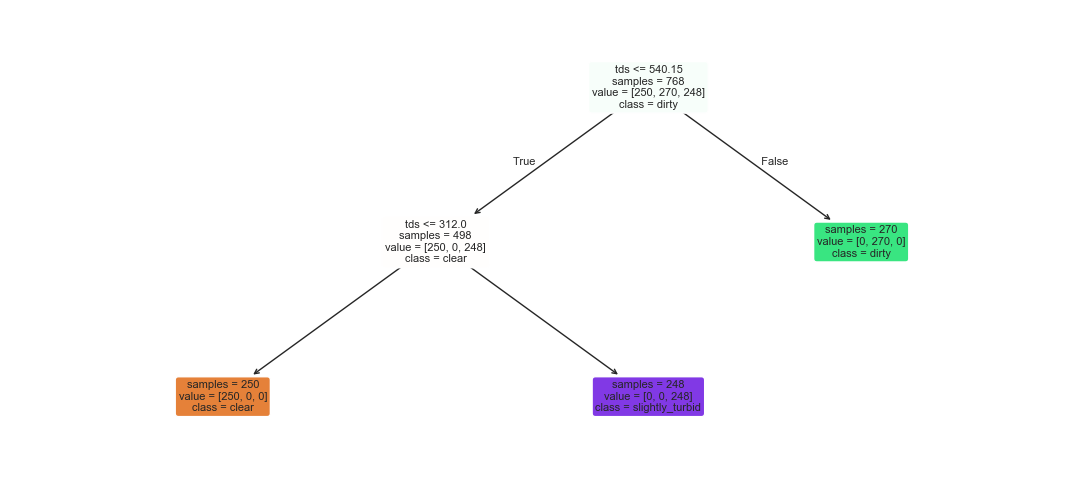

In [26]:
tree = fitted["Decision Tree"]
rules = export_text(tree, feature_names=MAIN_FEATURES)
print(rules)
with open("results/decision_tree_rules.txt", "w") as f:
    f.write(rules)

fig, ax = plt.subplots(figsize=(11, 5))
plot_tree(tree, feature_names=MAIN_FEATURES, class_names=list(tree.classes_), filled=True,
          rounded=True, impurity=False, fontsize=8, ax=ax)
fig.tight_layout()
fig.savefig("results/decision_tree.png", dpi=150)
plt.show()

### 8.5 Decision boundaries

How each model splits the TDS / turbidity plane. Points are the test readings.

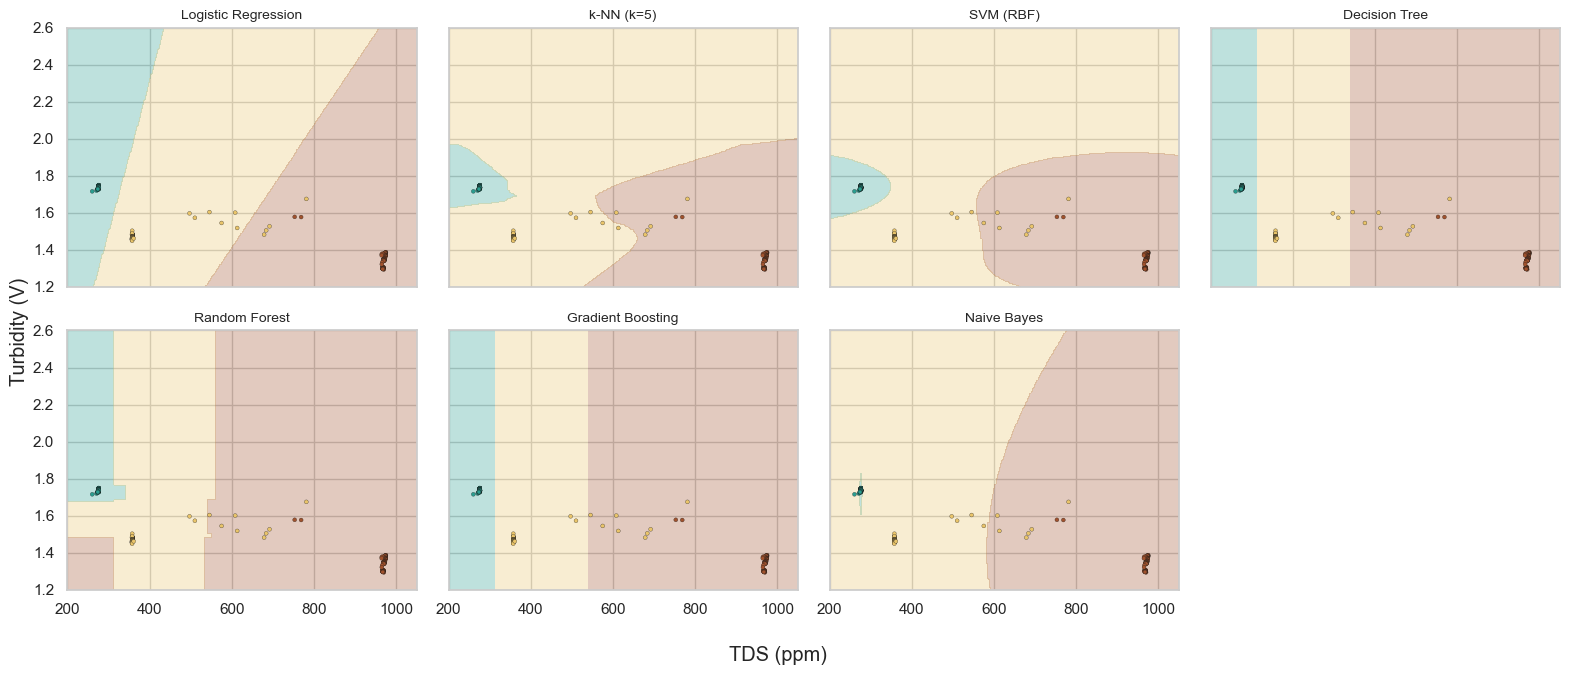

In [27]:
xx, yy = np.meshgrid(np.linspace(200, 1050, 300), np.linspace(1.2, 2.6, 300))
grid = pd.DataFrame({"tds": xx.ravel(), "turb_v": yy.ravel()})
code_of = {l: i for i, l in enumerate(LABELS)}
cmap = plt.matplotlib.colors.ListedColormap([COLORS[l] for l in LABELS])

fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 3.4 * rows_n), sharex=True, sharey=True)
for ax, name in zip(axes.flat, names_sorted):
    z = pd.Series(fitted[name].predict(grid)).map(code_of).values.reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=cmap, alpha=0.3)
    ax.scatter(test["tds"], test["turb_v"], c=test["label"].map(code_of).astype(int), cmap=cmap,
               s=8, edgecolor="k", linewidth=0.2, vmin=0, vmax=2)
    ax.set_title(name, fontsize=10)
for ax in list(axes.flat)[len(names_sorted):]:
    ax.axis("off")
fig.supxlabel("TDS (ppm)")
fig.supylabel("Turbidity (V)")
fig.tight_layout()
fig.savefig("results/decision_boundaries.png", dpi=150)
plt.show()

## 9. Which model fits on the ESP32

The ESP32 has about 320 KB of RAM and no Python, so the model has to become plain C code.
The table shows roughly how much each model would need to store.

In [28]:
def esp32_size(name, model):
    est = model[-1] if hasattr(model, "steps") else model
    if name == "Decision Tree":
        return est.tree_.node_count, "nodes", "if-else rules (export_tree.py already does this)"
    if name == "Random Forest":
        return sum(t.tree_.node_count for t in est.estimators_), "nodes", "100 trees of if-else, large header"
    if name == "Gradient Boosting":
        return sum(t.tree_.node_count for t in est.estimators_.ravel()), "nodes", "many small trees plus a sum"
    if name.startswith("k-NN"):
        return est.n_samples_fit_ * len(MAIN_FEATURES), "stored values", "must keep every training row"
    if name == "Logistic Regression":
        return est.coef_.size + est.intercept_.size + 2 * len(MAIN_FEATURES), "numbers", "a few multiply-adds"
    if name.startswith("SVM"):
        return est.support_vectors_.size, "stored values", "kernel over every support vector"
    if name == "Naive Bayes":
        return est.theta_.size + est.var_.size + est.class_prior_.size, "numbers", "mean/variance per class"

size_rows = []
for name in names_sorted:
    n, unit, note = esp32_size(name, fitted[name])
    size_rows.append({"model": name, "size": n, "unit": unit, "on ESP32": note})
esp = pd.DataFrame(size_rows).merge(results[["model", "test_macro_f1"]], on="model")
esp.to_csv("results/esp32_size.csv", index=False)
esp

,model,size,unit,on ESP32,test_macro_f1
0,Logistic Regression,13,numbers,a few multiply-adds,0.985
1,k-NN (k=5),1536,stored values,must keep every training row,0.981
2,SVM (RBF),96,stored values,kernel over every support vector,0.973
3,Decision Tree,5,nodes,if-else rules (export_tree.py already does this),0.969
4,Random Forest,1014,nodes,"100 trees of if-else, large header",0.969
5,Gradient Boosting,1476,nodes,many small trees plus a sum,0.969
6,Naive Bayes,15,numbers,mean/variance per class,0.965


## 10. Save the models

All trained models are saved so one can be chosen later. The Random Forest (10 trees, depth 3) is exported to
the firmware with:

```
python export_tree.py --csv data/iot_project_dataset_2026-11-03_labelled.csv
```

In [29]:
for name, model in fitted.items():
    file_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("=", "").replace("-", "")
    path = f"models/{file_name}.joblib"
    joblib.dump({"model": model, "features": MAIN_FEATURES, "labels": LABELS, "name": name}, path)
    print("saved", path)

saved models/decision_tree.joblib
saved models/random_forest.joblib
saved models/gradient_boosting.joblib
saved models/knn_k5.joblib
saved models/logistic_regression.joblib
saved models/svm_rbf.joblib
saved models/naive_bayes.joblib


## Summary

See the outputs above for the exact numbers. Points to keep in mind when choosing a model:

- **TDS carries most of the signal** in this dataset, because each label was made by adding
  salt. Turbidity alone separates the labels much less well (section 7.3).
- **Each label is a single session**, so the test set comes from the same session as the
  training set (just later in time). A new recording on another day would be a fairer test.
- **Temperature should stay out**: it only tells the sessions apart (room temperature).
- **Chosen for the ESP32: a small Random Forest (10 trees, depth 3).** It scores 0.973 on the
  test set with about 100 nodes, uses turbidity as well as TDS, and `export_tree.py` turns
  every tree into C with the same soft vote as scikit-learn. The large forest (100 trees) and
  Gradient Boosting are no better, k-NN and SVM must store many values, and the single
  Decision Tree only uses TDS. The other models serve as baselines.